<a href="https://colab.research.google.com/github/jungyouha/cds230/blob/main/lab7/pca_breast_cancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PCA on the Breast Cancer Wisconsin (Diagnostic) Dataset

**Goal:** Reduce 30 tumor measurements to a few principal components and see whether
malignant and benign tumors separate — *without* telling PCA which is which.

Dataset: UCI Machine Learning Repository — Wisconsin Diagnostic Breast Cancer (WDBC), 569 patients.

**Before running:** upload `wdbc.data` using the 📁 folder icon on the left
(or upload the zip file and run the unzip cell below).

In [12]:
# (Optional) If you uploaded the zip file instead of wdbc.data, uncomment and run:
# !unzip -o breastcancerwisconsindiagnostic.zip

## Step 0 — Load the data

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# wdbc.data has no header row, so we name the columns ourselves.
# 10 base measurements, each recorded 3 ways: mean, standard error (se), and worst (largest)
base = ['radius', 'texture', 'perimeter', 'area', 'smoothness', 'compactness',
        'concavity', 'concave points', 'symmetry', 'fractal dimension']
feature_names = ([f'{b} (mean)' for b in base] +
                 [f'{b} (se)' for b in base] +
                 [f'{b} (worst)' for b in base])

df = pd.read_csv('wdbc.data', header=None, names=['id', 'diagnosis'] + feature_names)

print('Shape:', df.shape)            # expect (569, 32)
print(df['diagnosis'].value_counts())  # M = malignant, B = benign
df.head()

Shape: (569, 32)
diagnosis
B    357
M    212
Name: count, dtype: int64


,id,diagnosis,radius (mean),texture (mean),perimeter (mean),area (mean),smoothness (mean),compactness (mean),concavity (mean),concave points (mean),...,radius (worst),texture (worst),perimeter (worst),area (worst),smoothness (worst),compactness (worst),concavity (worst),concave points (worst),symmetry (worst),fractal dimension (worst)
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Step 1 — Standardize (mean = 0, std = 1)
Features have very different scales (area is in the hundreds, smoothness is ~0.1). Without scaling, large-number features would dominate PCA.

In [14]:
x = df[feature_names].values   # 30 numeric features only (drop id and diagnosis)
y = df['diagnosis'].values     # labels kept aside — PCA never sees them

x = StandardScaler().fit_transform(x)

print('Normalized data stats:')
print('  Mean : {:.6f}  (should be ~0)'.format(x.mean()))
print('  Std  : {:.6f}  (should be ~1)'.format(x.std()))
print('  Shape:', x.shape)

Normalized data stats:
  Mean : -0.000000  (should be ~0)
  Std  : 1.000000  (should be ~1)
  Shape: (569, 30)


## Step 2 & 3 — Find principal components and project the data onto 2 of them

In [15]:
pca = PCA(n_components=2)
pcs = pca.fit_transform(x)

pca_df = pd.DataFrame(pcs, columns=['PC1', 'PC2'])
pca_df['diagnosis'] = y

print('PCA output shape:', pcs.shape)   # 569 patients x 2 components
print()
print(pca_df.head())

PCA output shape: (569, 2)

        PC1        PC2 diagnosis
0  9.192837   1.948583         M
1  2.387802  -3.768172         M
2  5.733896  -1.075174         M
3  7.122953  10.275589         M
4  3.935302  -1.948072         M


## Explained variance — how much information did we keep?

In [16]:
pc1_var, pc2_var = pca.explained_variance_ratio_

print('Explained variance per principal component:')
print('  PC1 : {:.1%}  - direction of greatest spread in the data'.format(pc1_var))
print('  PC2 : {:.1%}  - direction of second greatest spread'.format(pc2_var))
print('  ' + '-' * 45)
print('  Total: {:.1%}  of original information retained in 2D'.format(pc1_var + pc2_var))

Explained variance per principal component:
  PC1 : 44.3%  - direction of greatest spread in the data
  PC2 : 19.0%  - direction of second greatest spread
  ---------------------------------------------
  Total: 63.2%  of original information retained in 2D


## Visualize — 30 dimensions shown in 2

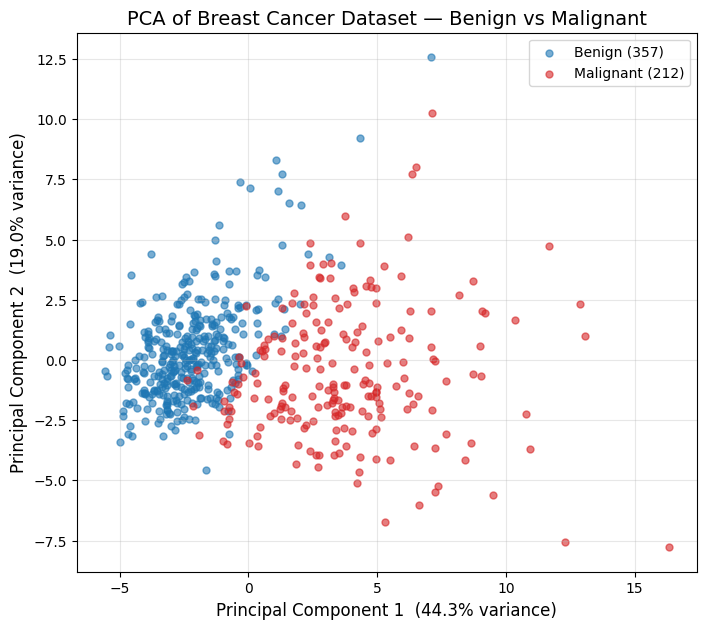

Plot saved as pca_breast_cancer.png


In [17]:
plt.figure(figsize=(8, 7))
for label, color, name in [('B', 'tab:blue', 'Benign'), ('M', 'tab:red', 'Malignant')]:
    mask = pca_df['diagnosis'] == label
    plt.scatter(pca_df.loc[mask, 'PC1'], pca_df.loc[mask, 'PC2'],
                c=color, label=f'{name} ({mask.sum()})', alpha=0.6, s=25)

plt.xlabel('Principal Component 1  ({:.1%} variance)'.format(pc1_var), fontsize=12)
plt.ylabel('Principal Component 2  ({:.1%} variance)'.format(pc2_var), fontsize=12)
plt.title('PCA of Breast Cancer Dataset — Benign vs Malignant', fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('pca_breast_cancer.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved as pca_breast_cancer.png')

## How many components do we need? (Cumulative explained variance)
PCA does not choose the number of components for us — we pick it based on a target such as 95%.

80% of variance needs  5 components (out of 30)
90% of variance needs  7 components (out of 30)
95% of variance needs 10 components (out of 30)
99% of variance needs 17 components (out of 30)


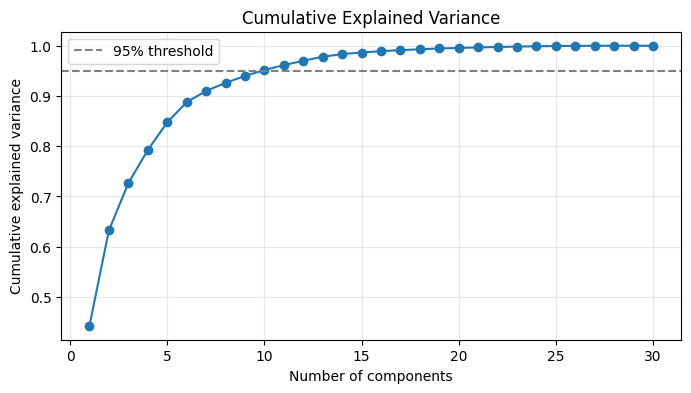

In [18]:
pca_full = PCA().fit(x)
cum = np.cumsum(pca_full.explained_variance_ratio_)

for target in [0.80, 0.90, 0.95, 0.99]:
    k = np.argmax(cum >= target) + 1
    print(f'{target:.0%} of variance needs {k:2d} components (out of 30)')

plt.figure(figsize=(8, 4))
plt.plot(range(1, 31), cum, marker='o')
plt.axhline(0.95, color='gray', linestyle='--', label='95% threshold')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('Cumulative Explained Variance')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('pca_breast_cancer_cumulative.png', dpi=150, bbox_inches='tight')
plt.show()

## What do PC1 and PC2 mean? (Loadings)
Loadings show how strongly each original feature contributes to a component. We use the top features to give each component a human-readable label.

In [19]:
loadings = pd.DataFrame(pca.components_.T, index=feature_names, columns=['PC1', 'PC2'])

for pc in ['PC1', 'PC2']:
    top = loadings[pc].abs().sort_values(ascending=False).head(6).index
    print(f'Top features for {pc}:')
    print(loadings.loc[top, pc].round(3).to_string())
    print()

Top features for PC1:
concave points (mean)     0.261
concavity (mean)          0.258
concave points (worst)    0.251
compactness (mean)        0.239
perimeter (worst)         0.237
concavity (worst)         0.229

Top features for PC2:
fractal dimension (mean)     0.367
fractal dimension (se)       0.280
fractal dimension (worst)    0.275
radius (mean)               -0.234
compactness (se)             0.233
area (mean)                 -0.231



## Group averages on each component

In [20]:
print(pca_df.groupby('diagnosis')[['PC1', 'PC2']].mean().round(2))

            PC1   PC2
diagnosis            
B         -2.21  0.35
M          3.71 -0.58


## Explanation for a general audience

I used the Breast Cancer dataset, which contains 569 samples with 30 features. I applied PCA to reduce the 30 features to two principal components. The two components explained 63.2% of the total variance. The graph shows that benign and malignant tumors are mostly separated, although some points overlap. I also found that 10 components are needed to explain 95% of the variance. This shows that PCA can simplify complex data while keeping important patterns.